# Christmas and New Year presence
Yogyakarta · JogjaPulse · Role 4

Open this notebook in Google Colab and choose **Runtime → Run all**. The notebook includes the upstream summary tables needed for this figure. The final cell displays the result and writes a PNG to the current directory.

In [1]:
from pathlib import Path
from io import BytesIO
import base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Image

PRIMARY_PERIODS = ['2021_Dec', '2022_Jan', '2022_Feb_P1', '2022_Feb_P2']
COLORS = {
    "education_campus": "#0072B2",
    "healthcare_hospital": "#CC6677",
    "commercial_mall": "#AA4499",
    "traditional_market": "#B57700",
    "tourism_site": "#00896B",
    "transit_hub": "#674EA7",
    "baseline_candidate": "#647482",
    "mixed_use": "#503E35",
    "no_selected_facility": "#CBD2D4",
}
LABELS = {
    "education_campus": "Campuses",
    "healthcare_hospital": "Hospitals",
    "commercial_mall": "Malls",
    "traditional_market": "Markets",
    "tourism_site": "Tourism",
    "transit_hub": "Transit",
    "baseline_candidate": "Baseline candidates",
    "mixed_use": "Mixed use",
    "no_selected_facility": "No selected facility mapped",
}
MISSING = "#d9dfe2"
BREAK = pd.Timestamp("2022-01-01")

PERIOD_NAMES = {
    "2021_Dec": "December 2021",
    "2022_Jan": "January 2022",
    "2022_Feb_P1": "February 1–15",
    "2022_Feb_P2": "February 16–28",
    "2022_Mar_Apr_Exploratory": "March–April (exploratory)",
}


## Source data
Snapshot of `data/gold/event_window.parquet`, `data/silver/daily_coverage_summary.parquet` generated by the merged project pipeline. Expand the folded cell to inspect the embedded data.

In [2]:
# @title Load the embedded summary tables
encoded = {'gold/event_window': 'eNqtmN1y2zgMhe/3KfIAqocACP70emcv9nrvNarNbTSVf0ay2+3b76Gcuu1YVoppEpFOZuxPMHmIA2jq9qehP3xsT2Xsj7tm151Ls8X08Th+bbZlGKZmO1ymcxmn67/tl/783E6X0+k4npt92fXdoR3L0J37z6U9jWUqh20B6Gt7/Lf9Usqnpp/aqd6ntB/G0n369qEP3VRw79LivVNTPve7+sk/2DG1f5ZtU/94R/yOfXN767Y77Po5SC96G7Rx5ERjDMoUHGlqfPNXN0ylkY1ryn+n4Th2Z3ylRfr2uN+Xcdt3Q7vvhqEh/nZtiNjHTMG7DHgiE7fsLljK/nhA2PvTZWoiNcp1RsDqEwWNyprYZzaBn0s3nJ+33Vja5+N06s/d0HhuJNcZ7JApc07is3cU1cQ+Hy9jP+3bqcciJ0QrdcZKsAuSgvOeIgK3BXweu11fV2Je4vFTOTfYI411RryOQ2D8UExOvJV8QKjt8+VDQ95h18L1FQGzBKl7Rw47ZwlYlwXnb6PSScSn6KJm9lh5NdDvBEffrg2p1MAlkCRno97JLeDzVGfacGYhySHEEEVTNIEX5Uaz3OaQowiH5DkT/kxqYv8sN9dErnMN2ItLmaNXnOdgC3hdbuQjlsKTOgbbCv6uNnz/WW0yLzDjbBAnoUzJWzYuLIqN823ULOSCF4ocfJSQUxMM9BWxIVwmLHBWxvZ5E3YtuTG2LYQUszgfgwn7SGvpqrXfIN8pja5KoxwoOyW8MzLyvQ26nthClQNr0OAgEG9F/5DZ8OU5Xl+RI2BGsDuH7IZ8qQZsXBZbug0EjYzmYUtcXYSQKpyB/tBK3SZHKFi9QwJC3KQm7qqVQgkBW8cuYplxOizg16xUOEYMx8lR9t7E/llxNOe2OeCkkXPAjNrCq22F1xSHRYaYsRjiQ84kGqzoB4pzGmD/TKrQhIplidOyl7rbqPQkDrogmJ6wNGSAr9RuLiFdRkTOPiSccRP3XnDcqNQZ4OpKKt6nEISrBRjAq4LDBibIIkSV6FFfqJrYy4KrqlBKcCXHDoLGuTFB1wVXa25RCCSgesvZiv5BcHXb0vUV505QamYkOo9CCDf7dWxeFhzdBoLWlByyHYykVhnU8Avd/wJ9JcVhDRyF6HC2AxyKTdzHinMbzWF2KF8r2aC2gF9RXFSc84Q0B2eVlG3sR4pD4c1oFWpThgyCvGmCriquHrksiaR2DSjhrOhFxQGrDo0ew0TQ8mEXfx2LHLaoOLkNKM7D/pDzpbZ9Cd9DDPQVxSVYXob3JYQMrJi4a4qLEVU3SlpFRoa/RhP4tRzHEjN+0eZkh6rIgl5uT7EQ6KOxuqgrInyKbPGuCy5ByRQYRwP1snCyoh8ILiFM9GTwkOjrYTFg6bX+tPoISiEUybhDzfuGphr0NVONAdFS7XoDqQ17rzdXG1TMNV6YnUe7kzLKLRw/C/jVIq5uodQCBgVzVhP7UdvgaiWbJCYkDDST0QZdEBzUFupcH2ZF5CEIWp04DCv6URGHnIyTgaATlnr9CQ63f3eHiuV3jnAttw3xNtDv/jNertqtDwify7B7/0RPoFy68evT9PKc8Wl+Arh4hzvR6cv1Bux75WkD8cY3gS+qD92U1vkN+D8rUGYFypuAl1U4X2+D/67EKmwv8+tvo3lZjXwb12Yz1ePJAaW0fn9i4l/VOj9WIqoE1DSRCNVHfRSDU2/hPlZhLRDQymdU0TAxQe9tAq8qEE4DD4CRB805IbGQiX1nuO7FcJOgEoV7kcrcxJqgK8oDOmTnNEbM2EQ0hEb0ouqA9ezrU5gAh6xp8CH2f+NcGts=', 'silver/daily_coverage_summary': 'eNq9XF1vHElyfL9f4Xf3DSo/6iP9ZsDeBwMHGLgF/EhwJfqWOIoUKMp7++8dWd1d2XNSc0cSexYLgZoROcGsyojIrKx+f/tyN73HHze/3f8y/X53+zx9eHp8+RWv/X7z9L83v93d/b1//Xj74W66/9RfuHt8718+3r7cPn/GNz6+f/rNX7h9fPpw+/D0+dON/0R/5dPth48Pdze/PN/d/n3qf7l//NvNx7vn+6f+Iz4+33+4ff598zOent/fP/pL+NCzv/sHf+01B/P+9v7h95uPn395uP/06937m3d3Dw+flldfnl5uH24+3N6/B8CHh7P3/uk7bt49fcBvb+kr3/pPb/3zd356eb5/9/LV7xxv3f3j4927l/Etnx/v/+/u+dPd8i3+Ij4FL93+7e7m47uXP3Fi+jPxnxNN8eW/pPRv/f9/TRV/9ncm4omn/7l7/3j3yUP00+0DfuyXf/q/vfmPu3fTz8+f7zZ/zO9SrW3KXJJMmssklBs+OMvEyoZ3KmW8eKKz/wIkB0jeAynTz79+fv4RjLnZZCVRm7QmYDL8YC4KxE3rjJHrqSVNrGrFpLaWA6QESNkDqdNPz/c/AFEtT5RKY8Sx1KlUFesYEdvGC8ZyomwsKVlhqVZKYNTAqHsY8/TX25fPz45y89F/AHJ+o39J0ipA5kQJIAUgaQVJJrKA1BMX01KE8H7SzWLnwJj3MJbpr58ffwBhFV9pRNB3Yzartqx0LTQAbpaZa5FAWAJh2UOYpr88Pf7IZsQ2JM4JeeNBbACLH17wq6sBwLrSuSB+gJ8S3ttsxhoQ6x5Emn7+/ENJDRAeS26IXClT0wbQ7Etu3CJjtAGxNPwCVApzgGwBsh3IPZkRStKqBTAV4IClw8wltQhllVKQ9KCqkrhtltsCph3IPrl51uTqqZ2xKVtbNmXBd45gctkmdx0oKU3x5VH0k0mBkVtKfcELieqMsQrRiKQaFVCjNBOEOXYlhdgQHUY/Wp0jJXt2+14UBHUGaYKvZpAZPG5cpWmqxSxpgAyxIT6If1RosmZ55p9CqS5hbERpIEwC7klggKrInAAYQkNyGP0k341aexABsaaeM+BwodTGSkdWG3NwOIXOkB5HP8l1hlrHyB2jdorMTGSBEWyUsNAGSm2pBcgQGspH0k92mGCe3BO71KxplcOWIrFVk6k2cGizutmPoTZUjqSfObXd/fiCZ5EFZUqUB0pCakPY1VppW/YJvaF6FPtA4Nz8ID7LnixpSezabGXIdlIRg5Aj/92qBY9TyA21w9inQC6Qz1x9tRvExpbVRi6NODY4NMHi18yasm0YMrSG7CDyKeIIISE8y2EutIQxU0oDIcJnIHxxkQQRDIgcQsPpKPqpIGozQTh6ygAdLxA9m+ZyIZ2clAopVWEI9gZi6AzTYfQDW+txBO/N2xGyOFhcV4q0k1WpWfBmw4pb5DWHzjAfST+tb8hsaV5u5W524TKsbRJ7r6zhUBuWA+kHtodIsNVm0VaEbfZoSVUGyjlf1DgX0UhtDr1hvZB+vkiec4Rf/gaIpFNkAYaFIrUnjmM0J8oFYyWQZwYLJd+fm10ZesP5Uv75DpRYaNQ20vpyZ5POP24qnZrGcjNsMTjAKhG3EEUOteFyGQF9B0QU/qZeJs7ll+Qlu1HDRtlAVWHjYHKTZdkUsRxaw/VCAvoOjOpi4x5xNhdQRhsuMlQ7iRKnKijKGskGZIgNt0sp6DtQzl63NplR5uSp0LdkE4q0wabImcjtJW+JMuSG7XIO+nacxbkSPK2+yDTVktviLjiRDM3BjrTKCUE1yyVISEJzJF1MQt8BM5HDBKjOQjAQwgtMUhswAdmsoThnapWDhiR0R+g4GnKqTNV6LPMEuvGGRHE1Rya/QpXe4lsafsuXX8Hou/IVEupf+j+7+a/bx12IgpBBHouHMXmSy0zmggJs3ZVyOqsd5l054+KAyDsQ/5iC/gChVGQLt9L3oybECAjTJMSjApPT1khCHAOhBELZQXiJBdpg/LLVBxwVtUvpmY2i1j8UcUVUNZpopW4deQuEGgh1B+FFDuh1iEhlkB/NQQRGb/8QlrlsIcL1kDQWRmpbIMyBMO8gvND+vIoRWoMiv8zuJ4dJg0e3UWorqzBZNhjPtEmWEhjLDsbLvM+rEOGxsHjODd3ceneg57P3gEYYG/xwqxnUmdmEA2MNjHUH4yWV12sIBTiq9M44jLm23Att/O6tSI6GbsNuhRyaNmm0yecWCNuFlHMRxLOWCuKAXMjcG+MgRm1LumBRYy+SKXOuTLXpJlssENpFjPPN+KSWCfuf5iYAdmWZ7QTMBEUI52YU/i1+GvbiADh395YvjyIc8UVGbHqmaNPuyrDINSmNTIGUt4xatvUKNgCGrBAdxjfqjXChOucyqqy5Ja7waTIQMhwafhfBD0u2hRiyQnwc4cCM+ZFHr/8RRkYVPWsf21AW9ZMuEHZKMLlWNxhDWEgOIxyB2BV21+2Eo95inMUPIldC/JRTG45ssxdDWkgPIhxN3qdvXOZsKZx1yRZqEcRciiGqIiAkLkE4FNJC+SjCwYd6d6dvRnJe1LmLIlprQGRY3pqKERUI9yaIoSxUDmKc4vnMtpgwSyvASi1WedNihvJsdmLICtWjGKd6PreUez2dkStLqyz5yq/5XKtyHfXqJoQhK9QOoxzoG4xCkcWFlX4og2IDtrUFKYJ/UOKwNfjK7UYMXSE7jHKYUPTBHmBP9YNr2OqlocdlXWlBPb1tS5SBkUNaOB1FOfD4dYK9gvvvEK2g+F8aemu2aDqRMUykoXBJcEGx1BzqwnQM5WBvtclK9S69I2rKS1NCvYOyIlzPEShBfWKhObSF+SDGgT9tUxNQXUeIyq7QktCOdV7mdkKyRxgpEIaysBxCOK4SIByReX5C3UHM+JAsS3tM8in5IVezlgm7M2/WOGSF9RjCYa/tUIzA7s1rXNYJD7V1jcU735uydAMwVIXzQXzDLm/GvTXW86Ku5Yqm1cYCIaoaFmrLUgfCEBUux9ENw1qbK0vHCBOzTk8UWmlb7IRa33tQhFdTqRu+CWHhehjfEMQPlJh4oUT4/hkjElgHJXrnMa8HwZtcCWXhdhDd+NgTSIRcWTyK4g2m+fTA1uIZfOMWdhwgbFY6hIXtKL7J3qJEsnhP3iEWN7DzwSWt/W6Fg4DzSRlK0w+MIl8khEXSMYxTIHmUMiz0jBB5oaOTvJL2uYOIVZYQFaGDCMfPCghuJpUlhPOEzHz2u3C2ohoocImGHIdTtLVFwtGr471eHV/KOD/d/XLz37SD0jshPVGXjC6S1oEtVKwLynqqmfz0H7RJYXI42nW8167jy1nnVZy5HwA34yVncqvrhuS1mePRbGS14l83PwouAVQCqOwAvZR5XsVZcvYiq/c/gbBxn3bsZ62J1lUvJ93WLxIwNWDqDszL2Od1kFhtH97iOXdQVy+zPIXrSpHIHS+sxokWBcgcIPMOyAsJ6AuUZxkuFShTzjORw17k2TjmIkwjlOMQ2McsNiteAmXZQXkRBb2KsXqSKzztstx98rFHsnrLbE2fUlDVkpm3ckvWAFkDZN0BeRkPvb7ePZKt1ZmKYB7WTdnKWlO/EskWINuBVFQyGB0GI+m83plWzTHOgVIrIpnqMgwXKC1Q2rFUhB8Iacx1Nrt+RJCX+She+3nQRmQSKNMWLzRwjnYe77Xz3oiJvPL34tQWmK2tzC6WZcBMqpvOaA6cIUBEx1ERSgWXcST3jFJZdJk9orUhpXxa9uTMmZE/FPpDfCAVwUS6+rSFMEHyy9xMTtiKQ3221Y3RBmaoD8lhXKTztAfyY7GVRrSGstpYcPApONVMUkrj1Iijtcd7rb03oSLJfoKJD16MpRRbZ83GhKbSiar/S81Qz5Y4uIhCeygfyEU+Jozk6ecJc/LoOmxvGjB7B5e4VtEkwUUU2kPlu7gozlo7TN5pUSF9Jmi3zCcLjMp1ntRE0NratwfKUrkadir59PsmxUN9qL4FFe3BRDUG1lFu/YBGPF4dJvs5wlKRyWkoT8/yQBnyQ+3HiWgXI0JXkvbbFQ1FbF1GsBE503FLxXxODrWu9uZuYAzxIXsDHuLdw3enRO2DKQCptJTfbjvzaLNsazKKXcmhPJx+mIV2IBLqg8lX0m/7mA/q5nmtiaWsh13plL9Wl3E0+3iv2fdNJLSz1q3Bozeo9eSZQ/3EukOEo1gkhxDFljPeWfQxyJxDc5jfgIL2QKpHzytF7cMjSZfUTrzeUyEozhbjxg1xKA7Lm7ihHZjmBthFD7FkP7yRBaY3SheYcJZxUQUMsIEZosN6IANVv62SvfE8B5PNlmCW9bIKyWkZ5NLGcE0leJJDdDgfxkDVp7Czt1Dx4YhfobkJbYN/AHH4yd5b20AMxeFyHAFVX2NQi3civYT0aal5tW2tyAhmbZ53he0QZP1mtUNvuB5FQO4nsN3Ye+O1J/ey1EzrVRpAjLG9vtoBMcSG22EE1KvGygihOFo/818x1jIwltJ00x1aMEq0hmSvNSSXEtBfbp9v/v3j881//uPjw9Pz7cvT89ls2gayOwvqFza7g6PiLb4+JwmMC+R08mlNSdVQm3mvPyBzQOYdyBfT0eWgfR7W190Pj5FIxecugBnmXAfkMWXacQdiCcSyg/hSZvqGKHsJjNzx2RXvy3HL/aqsT6Mu4kmECrjlkqH9vYUdkDUg6w7ky2jqGwCbq5T2ownfv+yE0AG3Ejt5DBuX3sELxDkQ5x3EF7LWH0DeEoQ3Q9TvNM07Wbwiz9SrEhsxXs4ulnuBmyCXgFx2IF/EYZcDzgaY7NW7qPR7gn532s9U14Mr38bL3JAPglLdZF4NvHUH72WE9g1pl/ulS6iYXyQyHxVk9eaYLFvCUJKAnS1z7ePJm7RrAbd9E7dtq7fX4X75p7ijKj7B2EfnM1jD3HethrWc1qvK8+jOJrwWeO2KxOYNXCqgMcFHwFqVOcLGI8JbKyOcB+LRf5K9/tMRxJbdaLOnGvjWD7/ADrAGE1JLVsQxRlFTrZFyFHpHdCVeyzJf3IPcwf01P/NiMR+EHAGe44oiR6jmFluYQuuIr0VqkASUNS5a2LjFb5cytgg0bXFlDdGVOK2zQBs6R3IdPlNYbuuWB26i+okOY9vGZFI7+ci9qB+dKcrEwBoCR3otLkteJSRRHw+fqh8tYhu77tUV7XxrcyW0zUYIdaN8LZ+WgRR8IH3fVmcI37elrU0r7NsYkPTT5YAbykblilQ2N4A7M+jUfLSKoRPw5yPTcsPWjnsXgTi0jer1qEz9aHx+lEn1+le8qzk1iRD3Iegxp7HZwKFu1K7l0Pzefm2+I9w9KPt9c/WHN4xxStiHqgKjk3SZ4w7EoW9k1yIzNziw7XDAy2CW51wFv62jRHYq4A8DP/cL3jrgcogbpyuxWXe7xUfOqwFj9ZYrQzLW2y71BFXOCUpXBKZ9U8hxCBvTlfhM+0mG+p3a5nC9mOR+BDzYN5WyfYpDwA1hY74Wn/lUB1yXezOXjYKanp0nWtMR3nV4gmDjY+tyKBvL9fhMq58ceLks+BxLbs3wF6fcIcUI/YbTAnHoG+sVrZkXyT7s4QpH2Ai1MzDCOght87QMLzQCcUgc5ysRmjZ/Ok6XOL9v7/14n+B0lY4Qrw8gWQbZA3CIHJer8Zl3zYCjdsXwyS/riG3cFYcqp9aGRauBNySO65UIrXj30VtU7iWB1js9iJtxHeH98hEGM8TQN27XIjS/BstqumzffhjvJmgM+yHhaFPOR2HBIW5s1yI0pPwEqvKDJYHdcffg15egDGutaSg3fC7LZ5yMQy4kxE3SFQmNVw1uPs/knXMUDTW3oW/nD3mK9o6Evgldjc+koSKm3pgmlBd+COV1Bq+FZjmd9VVHr0Sjsap7jVV9ezbr2lDm7QAz4xoLjJCyEd2s/tQ3xRb2nRFoOdDyDtq3rzNRDlXr7WpUFZ0k/Lkhtp6i1NO48ALcpqPxoNFR1b2Oqr41lTnIyv4IKF/33M+i3ObkdRDvVM/hBlgNsLoD9q2ZTPChTXs5gfrHu2Z+k6zk9XlG+SRnxz8BNgfYvAP2zXmMEclaadmvzUdmYdKKq8US25JVYx5zsxFKwC07cA/gMfbLed4nYfbHvzU/Jsr+sIR14PHUiorROOIPwDUA1x3Ab89jfqG/+IEA+w2PHuB54IjX7XD2kLBhGjSaqLrXRH17HvNzy+a3o7wzXclPhiAQxS+iLWiheVxAt/OjPTbRtUBr1+Ixr4UrShyfmsKucEvp10hztlUk1vuZ83TPQDvap7rXPn17FsOKw39T94zQWfF63juqaQ3t2R20jaBRCBrRtVhM142Q/blsfgLXxWG9poTI+hkQ6rfsl3o325ZC0IivRWPi27VmPwLy4IrOcGX1uoBbt0+j2eyE0DOS69GYVHjb5ID9jmc/CIAlK6NYK6cz2h2P/9Bon+pe+/QIGoNv8Scc1G4fiz/VoD/Sso+EzY7h/Ol3YXAoZI3ytWgMxS9y3reDP9YLW5gMPhccsEZXvTEFN1mb2GjtaXRPda97eoQbY1r2Ajyvz0vPYszrY3Xq6ey5pgE2BI3qdUjMj4dbnw1z49h8wsVPtIvRGtizp5nUEn6BQs6oXYnFtD+40S9IsHlv17s4sAHwD9HVQ4GWkkqf895shJAzsquZMZ/q94cjutGFJSAfgfFOdRlG9zzLBlwOPeN0RRZr/twTN2MItPed5+1Q0yjSthcxtQaLcWga0/VYTP1YxYMFJquleKTd3vBgsVpAB635A68pbViMQ9WYr1VUghLMxwbYUK75s1JBWj7Ck1a049J/8suHG7QhaixXM2Mo1Bs5KaFUK31sFLYhj/GGveN3jY6p7nVM35zIUNJOhq2A2JJf78pz/0bSiO35UUowA4eecb4Wj/m+bZ3G2Jshad63YwDqlX0bgsblWjzWTyfwn/d2nSC8siXvixR6/XRCo1Oqe53SQ4jMGyJWfJoBW6Jqjxr5E1bSHzZEOHSN2/WYzBvP7r780e21+aOdkz+1RkYH56tPj9Polupet/QAOwZf06w/ABb1mrdDXCaKxGDOXi9PQtckXY3I2uwaEFOQWEsl97KyjEcUQ9bOHxH6p/8Hsy0+kA=='}
tables = {k: pd.read_csv(BytesIO(zlib.decompress(base64.b64decode(v)))) for k, v in encoded.items()}
def read(layer, name, columns):
    frame = tables[f'{layer}/{name}'].copy()
    missing = set(columns.split()) - set(frame)
    if missing:
        raise ValueError(f'{name} is missing {sorted(missing)}')
    return frame
def gold(name, columns):
    return read('gold', name, columns)
for key, frame in tables.items():
    print(key, frame.shape)
    display(frame.head(3))


gold/event_window (70, 11)


,sampling_period,date,category,cells,clusters,cells_with_support,median_relative_presence,day_of_week,is_sample_break,median_baseline_days,evidence
0,2021_Dec,2021-12-24,baseline_candidate,435,435,435,1.010358,4,False,3.0,exploratory
1,2021_Dec,2021-12-24,commercial_mall,12,12,12,1.112479,4,False,3.0,exploratory
2,2021_Dec,2021-12-24,education_campus,71,52,71,1.054817,4,False,3.0,exploratory


silver/daily_coverage_summary (151, 23)


,date,date_wib,year,month,day_of_week,day_name,is_weekend,is_nataru_window,is_anomalous_date,is_sample_break,...,is_ordinary_weekday,is_ordinary_weekend,daily_published_cells,daily_total_maids_all_cells,daily_published_cells_common90,daily_total_maids_common90,daily_published_cells_strict90,daily_total_maids_strict90,expected_cells_universe,daily_cell_coverage_pct
0,2021-12-01,2021-12-01 00:00:00+07:00,2021,12,2,Wednesday,False,False,False,False,...,True,False,1778,52603,456,31581,253,24298,5715,31.111111
1,2021-12-02,2021-12-02 00:00:00+07:00,2021,12,3,Thursday,False,False,False,False,...,True,False,1589,96018,470,57921,264,45847,5715,27.804024
2,2021-12-03,2021-12-03 00:00:00+07:00,2021,12,4,Friday,False,False,False,False,...,True,False,1495,106823,467,67439,264,52682,5715,26.159230


## Build the figure
Each event date is compared against non-event dates of the same weekday in the same sampling period. January 1, 2022 is an upstream sampling break and its estimate is withheld.

In [3]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlecolor': '#224853'})

def heading(fig, title, description):
    fig.suptitle(
        title + "\n" + description,
        x=0.025,
        ha="left",
        fontsize=15.5,
        color="#163c45",
    )


def save(fig, path):
    fig.savefig(path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def holiday(path):
    event = gold(
        "event_window",
        "date category sampling_period median_relative_presence cells_with_support evidence",
    )
    cov = read(
        "silver", "daily_coverage_summary", "date daily_cell_coverage_pct"
    ).copy()
    cov.index = pd.to_datetime(cov.date)
    dates = pd.date_range("2021-12-24", "2022-01-02")
    cats = [c for c in LABELS if c in set(event.category)]
    rows = (len(cats) + 1) // 2
    fig = plt.figure(figsize=(13, 2.05 * rows + 2.5), layout="constrained")
    layout = fig.add_gridspec(rows + 1, 2, height_ratios=[1] * rows + [0.95])
    usable = event.loc[
        event.evidence.eq("exploratory"), "median_relative_presence"
    ].dropna()
    limits = (min(1, usable.min()) - 0.05, max(1, usable.max()) + 0.05)
    for i, cat in enumerate(cats):
        ax = fig.add_subplot(layout[i // 2, i % 2])
        cat_rows = event[event.category.eq(cat)]
        for _, group in cat_rows.groupby("sampling_period"):
            y = group.set_index(pd.to_datetime(group.date))
            series = y.median_relative_presence.where(
                y.evidence.eq("exploratory")
            ).reindex(dates)
            series.loc[BREAK] = np.nan
            ax.plot(dates, series, color=COLORS[cat], marker="o", markersize=4, lw=2)
        ax.axhline(1, color="#778b92", ls=":", lw=1)
        ax.axvspan(
            BREAK - pd.Timedelta(hours=8),
            BREAK + pd.Timedelta(hours=8),
            color="#f3dfce",
        )
        if i == 0:
            ax.text(
                BREAK,
                limits[1] - 0.03 * (limits[1] - limits[0]),
                "1 Jan break\n(withheld)",
                ha="center",
                va="top",
                fontsize=7.5,
                color="#7c4d25",
                fontweight="bold",
            )
        ax.set(
            ylim=limits,
            xticks=dates[[0, 4, 8, 9]],
            xticklabels=["24 Dec", "28 Dec", "1 Jan", "2 Jan"],
        )
        supp = cat_rows.loc[
            cat_rows.evidence.eq("exploratory"), "cells_with_support"
        ].dropna()
        supp_label = (
            f" ({int(supp.min())}–{int(supp.max())} cells)"
            if not supp.empty and supp.min() != supp.max()
            else (f" ({int(supp.iloc[0])} cells)" if not supp.empty else "")
        )
        ax.set_title(
            LABELS[cat] + supp_label,
            loc="left",
            color=COLORS[cat],
            fontweight="bold",
            fontsize=11.5,
        )
        ax.spines[["top", "right"]].set_visible(False)
    if len(cats) % 2 == 1:
        legend_ax = fig.add_subplot(layout[rows - 1, 1])
        legend_ax.axis("off")
        holiday_handles = [
            Line2D(
                [0],
                [0],
                color="#0072B2",
                marker="o",
                markersize=4,
                lw=2,
                label="Relative presence vs matched weekday in period",
            ),
            Line2D(
                [0],
                [0],
                color="#778b92",
                ls=":",
                lw=1.2,
                label="1.0 = Non-holiday same-weekday baseline",
            ),
            Patch(
                facecolor="#f3dfce",
                edgecolor="none",
                label="1 Jan 2022 sampling break (estimate withheld)",
            ),
            Patch(
                facecolor="#43828a",
                edgecolor="none",
                label="Daily grid publication coverage (% of 5,715 cells)",
            ),
        ]
        legend_ax.legend(
            handles=holiday_handles,
            loc="center left",
            frameon=True,
            facecolor="white",
            edgecolor="#d9dfe2",
            fontsize=9.5,
            title="How to read this chart (exploratory RQ3)",
            title_fontsize=10,
        )
    bottom = fig.add_subplot(layout[-1, :])
    bottom.bar(
        dates, cov.daily_cell_coverage_pct.reindex(dates), color="#43828a", width=0.68
    )
    bottom.axvspan(
        BREAK - pd.Timedelta(hours=11),
        BREAK + pd.Timedelta(hours=11),
        color="#f3dfce",
        zorder=0,
    )
    bottom.set(
        xticks=dates, xticklabels=dates.strftime("%d %b"), ylabel="Grid published (%)"
    )
    bottom.set_title(
        "Daily publication coverage", loc="left", fontsize=12, fontweight="bold"
    )
    tourism = event[
        event.category.eq("tourism_site") & event.evidence.eq("exploratory")
    ]
    tourism = tourism.set_index(pd.to_datetime(tourism.date)).median_relative_presence
    christmas = tourism.get(pd.Timestamp("2021-12-25"), np.nan)
    later = tourism.get(pd.Timestamp("2021-12-29"), np.nan)
    result = "January 1 is skipped because the sample changed."
    if pd.notna(christmas) and pd.notna(later):

        def describe(ratio):
            return f"{abs(ratio - 1):.0%} {'above' if ratio >= 1 else 'below'} matched same-weekday baseline"

        result = (
            f"Tourism cells were {describe(christmas)} on Dec 25 and "
            f"{describe(later)} on Dec 29.\n" + result
        )
    heading(
        fig,
        "Christmas and New Year in Yogyakarta",
        "What we built: Lines compare each holiday date with the same day of the week outside the holiday.\n"
        "The bottom bars show how much of the map had published data.\n"
        f"What we found: {result}",
    )
    save(fig, path)


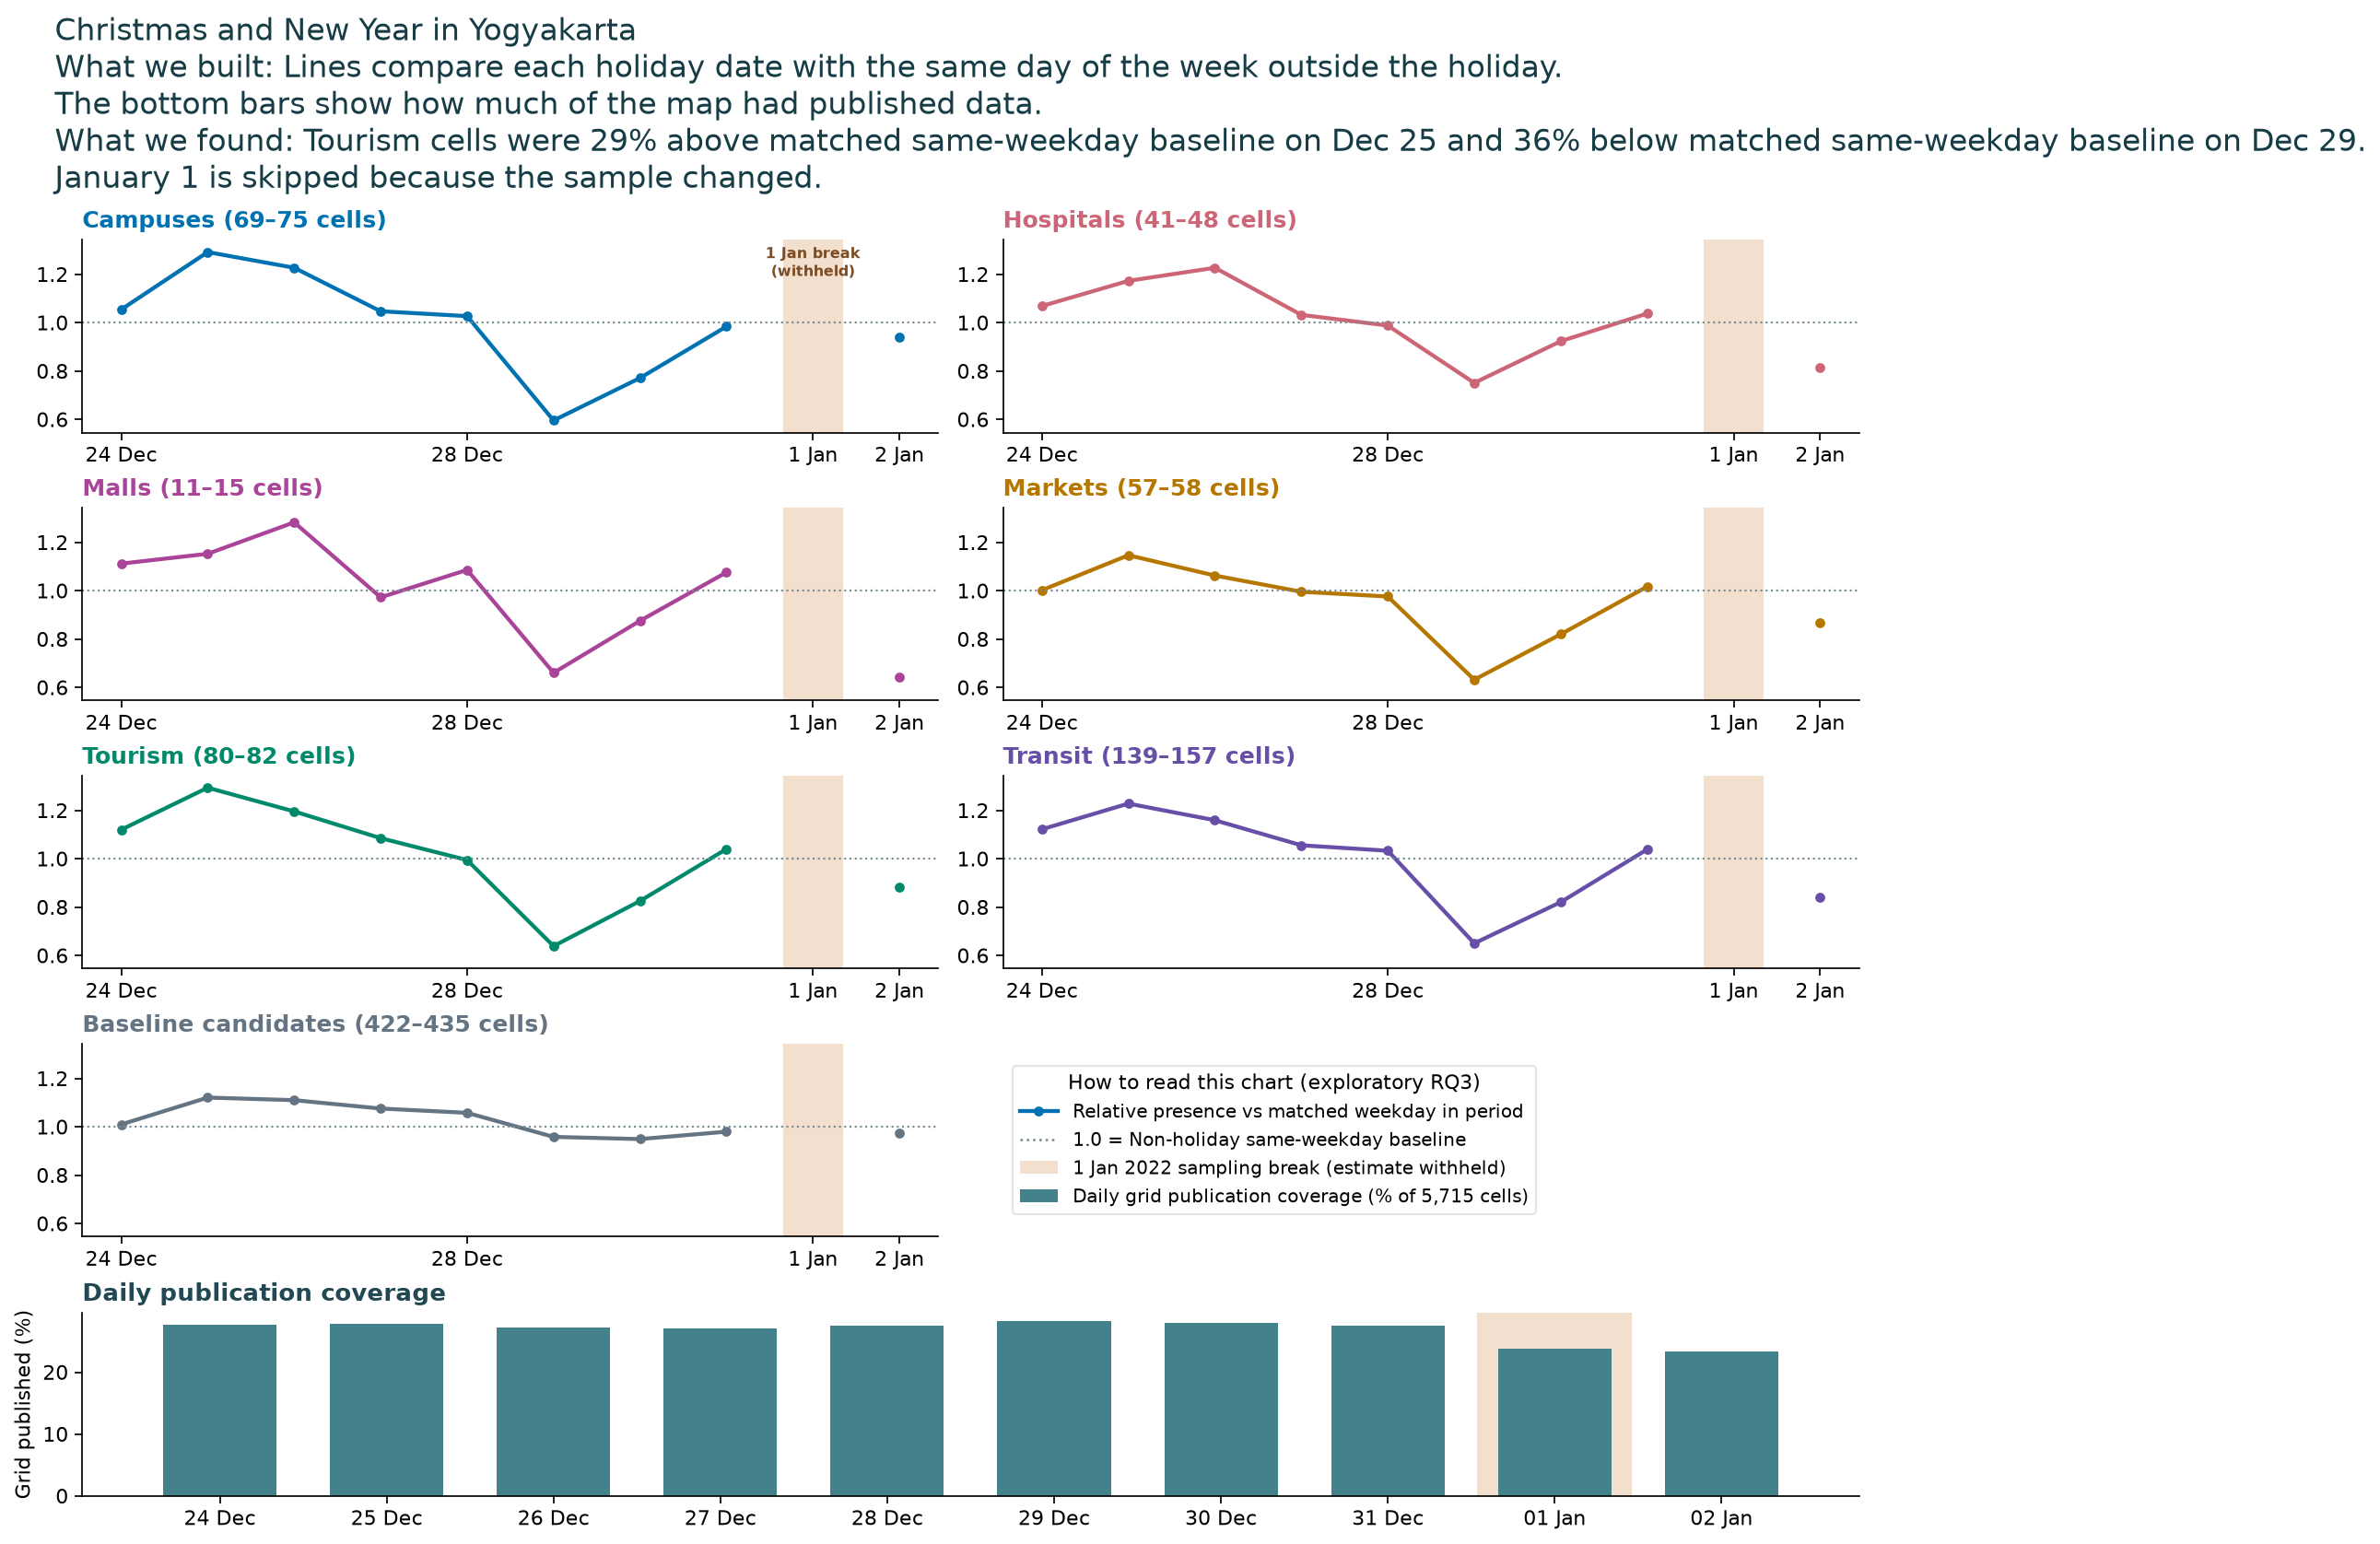

In [4]:
output = Path('nataru_timeseries.png')
holiday(output)
display(Image(filename=str(output)))